In [59]:
# 10.1 FashionMNIST 다운로드

from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
  target_idx = defaultdict(list) # 기본값이 있는 딕셔너리 클래스를 활용해 데이터 색인 값 가져옴
  for idx, label in enumerate(dataset.targets):
    target_idx[int(label)].append(idx)

  indices = list(
      chain.from_iterable(
          [target_idx[c][:max_len] for c in classes]
      ))
  return Subset(dataset, indices) # 해당 색인 값에 해당하는 데이터세트 추출

train_dataset = datasets.FashionMNIST(root='./datasets', download=True, train=True)
test_dataset = datasets.FashionMNIST(root='./datasets',download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx # 클래스 ID와 클래스가 매핑된 값 확인

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(
    dataset=train_dataset,
    classes=class_to_idx.values(),
    max_len=100
)

subset_test_dataset = subset_sampler(
    dataset=test_dataset,
    classes=class_to_idx.values(),
    max_len=100
)

print(len(subset_train_dataset))
print(len(subset_test_dataset))
print(train_dataset[0])

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
1000
1000
(<PIL.Image.Image image mode=L size=28x28 at 0x78672F6FC6D0>, 9)


In [60]:
# 10.1 이미지 전처리

import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path='google/vit-base-patch16-224-in21k' #ImageNet-21k 데이터세트 이용ㅇ
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size['height'],
                image_processor.size['width']
            )
        ),
        transforms.Lambda( # 단일 채널을 복제해 다중 채널로 이미지 변환
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

print(image_processor.size)
print(image_processor.image_mean)
print(image_processor.image_std)

SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
(0.5, 0.5, 0.5)
(0.5, 0.5, 0.5)


In [61]:
# 10.3 데이터로더 적용

from torch.utils.data import DataLoader

def collator(data, transform) : # 집합함수(collate_fn)을 적용하기 위해 collator 생성
  images, labels = zip(*data)
  pixel_values = torch.stack([transform(image) for image in images])
  labels = torch.tensor([label for label in labels])
  return{'pixel_values': pixel_values, 'labels': labels} #ViT모델의 입력
  # pixel_values=(배치 크기, 채널 수, 이미지 높이, 이미지 너비) / labels=클래스 색인 값

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform),
    drop_last=True
)

valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform), # collate_fn를 적용해 미니 배치의 샘플 목록을 병합
    drop_last=True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
  print(key, value.shape)

pixel_values torch.Size([32, 3, 224, 224])
labels torch.Size([32])


In [ ]:
# 10.3 사전 학습된 ViT 모델

from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path='google/vit-base-patch16-224-in21k',
    num_labels=len(classes),
    label2id=class_to_idx,
    ignore_mismatched_sizes=True
)

print(model.classifier)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=10, bias=True)


In [ ]:
# 10.5 패치 임베딩 확인

print(model.vit.embeddings)

batch = next(iter(train_dataloader))
print('image shape:', batch['pixel_values'].shape)
print('patch embeddings shape:', model.vit.embeddings.patch_embeddings(batch['pixel_values']).shape)

print('CLS+patch size embeddings shape:', model.vit.embeddings(batch['pixel_values']).shape)

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
image shape: torch.Size([32, 3, 224, 224])
patch embeddings shape: torch.Size([32, 196, 768])
CLS+patch size embeddings shape: torch.Size([32, 197, 768])


In [ ]:
# 10.6 hyperparameter 설정

from transformers import TrainingArguments
# TrainingArguments는 학습 매개변수 클래스로, 모델 학습에 필요한 다양한 인자들을 저장하고 관리할 수 있음

args=TrainingArguments(
    output_dir='../models/ViT-FashionMNIST',
    save_strategy='epoch',
    eval_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

In [ ]:
!pip install evaluate

In [ ]:
# 10.7 Macro Average F1_score


import evaluate
import numpy as np

# eval pred는 모델이 예측한 결괏값을 전달받으며, 모든 클래스에 대한 예측값이 포함되어 있으므로 가장 확률이 높은 것을 선택
def compute_metrics(eval_pred):
  metric = evaluate.load('f1')
  logits, labels = eval_pred
  predictions = np.argmax(logits, axis=-1)
  macro_f1 = metric.compute(
      predictions=predictions,
      references=labels,
      average='macro'
  )
  return macro_f1

In [ ]:
# 10.8 모델 학습
from transformers import Trainer

def model_init(classes, class_to_idx):
    model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
    num_labels=len(classes),
    id2label={idx: label for label, idx in class_to_idx.items()},
    label2id=class_to_idx,
    )
    return model

trainer = Trainer(
    model_init=lambda x:model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor # 토큰을 임베딩해 모델 입력으로 사용하도록 토큰 분리 작업 수행
)

trainer.train()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1
1,No log,1.965665,0.719354
2,1.982741,1.749784,0.798350
3,1.982741,1.679720,0.806947


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=189, training_loss=1.8775109185112848, metrics={'train_runtime': 182.6685, 'train_samples_per_second': 16.423, 'train_steps_per_second': 1.035, 'total_flos': 2.32492637712384e+17, 'train_loss': 1.8775109185112848, 'epoch': 3.0})

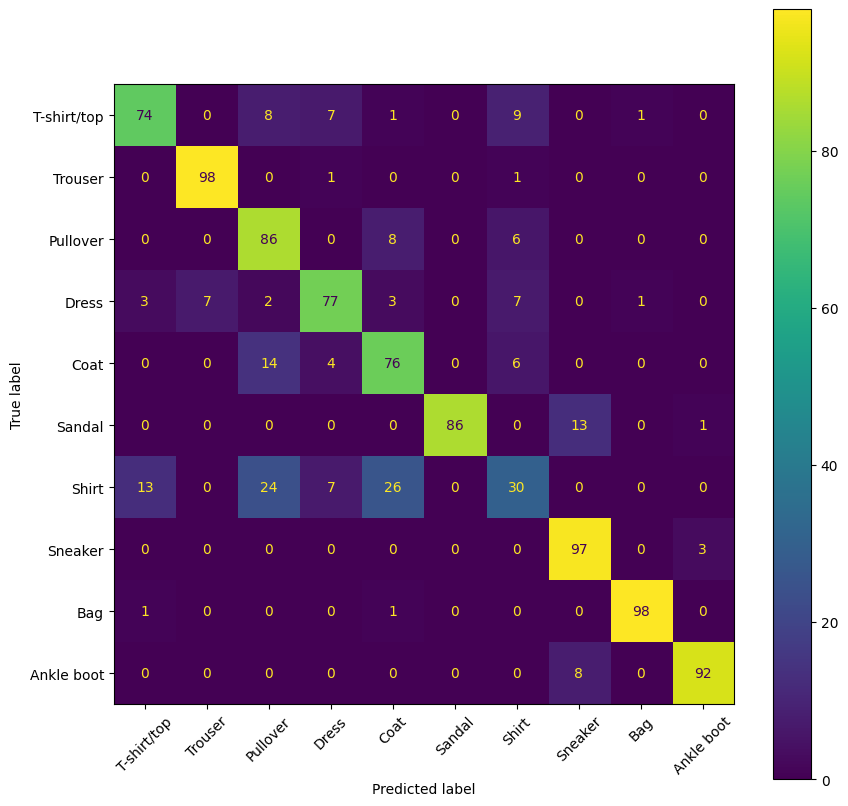

In [ ]:
# 10.9 confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(test_dataset=subset_test_dataset)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
display.plot(xticks_rotation=45, ax=ax)  # xticks_rotations -> xticks_rotation 오타 수정
plt.show()

**상대적 위치 편향 계산**

In [ ]:
# 10.10 상대적 위치 편향 계산

import torch

window_size=2 # 여러 개의 이미지 패치를 포함하는 격자의 크기, 윈도 내외부의 패치를 구분해줌
coords_h = torch.arange(window_size)
coords_w = torch.arange(window_size)
coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing="ij"))
# torch.meshgrid 함수는 coords_h 배열 값(i)과 coords_w 배열 값(j)으로 사각형 격자(ij)를 만드는 데 사용되며, 사각형의 X좌표 Y 좌표에 해당하는 배열 반환한다.
coords_flatten = torch.flatten(coords, 1)
relative_coords = coords_flatten[:, :, None]-coords_flatten[:, None, :]
print(relative_coords)
print(relative_coords.shape)

tensor([[[ 0,  0, -1, -1],
         [ 0,  0, -1, -1],
         [ 1,  1,  0,  0],
         [ 1,  1,  0,  0]],

        [[ 0, -1,  0, -1],
         [ 1,  0,  1,  0],
         [ 0, -1,  0, -1],
         [ 1,  0,  1,  0]]])
torch.Size([2, 4, 4])


In [ ]:
# 10.11 X,Y 축에 대한 위치 행렬

x_coords = relative_coords[0, :,:]
y_coords = relative_coords[1, :, :]

x_coords += window_size -1
y_coords += window_size -1
x_coords *= 2*window_size -1
print(f'x_coords shape: {x_coords.shape}')
print(f'y_coords shape: {y_coords.shape}')
relative_position_index = x_coords + y_coords
print(f'X, Y축에 대한 위치 행렬:\n{relative_position_index}')

x_coords shape: torch.Size([4, 4])
y_coords shape: torch.Size([4, 4])
X, Y축에 대한 위치 행렬:
tensor([[4, 3, 1, 0],
        [5, 4, 2, 1],
        [7, 6, 4, 3],
        [8, 7, 5, 4]])


In [ ]:
# 10.12 X,Y축에 대한 상대적 위치 좌표 변환

num_heads = 1 # num_heads는 MSA를 계산할 때 사용된 헤드 수로, 예저에서 1개로 설정함
# relative_position_bias_table은 헤드별로 0~8번까지 9개의 상대적 위치 편향을 가지는 테이블 의미
relative_position_bias_table = torch.zeros(
    ((2 * window_size - 1) * (2 * window_size - 1), num_heads)
)
relative_position_bias = relative_position_bias_table[relative_position_index.view(-1)]
relative_position_bias = relative_position_bias.view(
    window_size*window_size, window_size*window_size, -1
)

print(relative_position_bias.shape)

torch.Size([4, 4, 1])


** 스윈 트랜스포머 모델 미세 조정**

In [62]:
# 10.13 사전 학습된 스윈 트랜스포머 모델
from transformers import SwinForImageClassification

model = SwinForImageClassification.from_pretrained(
    pretrained_model_name_or_path='microsoft/swin-tiny-patch4-window7-224',
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("L", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("| L", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        if sssub_name == "projection" :
          print("| | L", sssub_name, sssub_module)
        else:
           print("|| L", sssub_name)

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


swin
L embeddings
| L patch_embeddings
| | L projection Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
| L norm
| L dropout
L encoder
| L layers
|| L 0
|| L 1
|| L 2
|| L 3
L layernorm
L pooler
classifier


In [63]:
# 10.14 패치 임베딩 모듈

batch = next(iter(train_dataloader))
print("이미지 차원:", batch["pixel_values"].shape)

patch_emb_output, shape = model.swin.embeddings.patch_embeddings(batch["pixel_values"])
print("모듈:", model.swin.embeddings.patch_embeddings)
print("패치 임베딩 차원: ", patch_emb_output.shape)

이미지 차원: torch.Size([32, 3, 224, 224])
모듈: SwinPatchEmbeddings(
  (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
)
패치 임베딩 차원:  torch.Size([32, 3136, 96])


In [64]:
# 10.15 스윈 트랜스포머 블록

for main_name, main_module in model.swin.encoder.layers[0].named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
      print("└", sub_name)
      for ssub_name, ssub_module in sub_module.named_children():
        print("|└", ssub_name)

# blocks와 downsample로 이루어져, blocks는 스윈 트랜스포머 블록을 의미하며, downsample은 패치병합 의미

blocks
└ 0
|└ attention
|└ layernorm_before
|└ layernorm_after
|└ mlp
|└ dropout
|└ drop_path
└ 1
|└ attention
|└ layernorm_before
|└ layernorm_after
|└ mlp
|└ dropout
|└ drop_path
downsample
└ reduction
└ norm


In [65]:
# 10.16 SwinLayer 구조
print(model.swin.encoder.layers[0].blocks[0])

SwinLayer(
  (attention): SwinAttention(
    (q_proj): Linear(in_features=96, out_features=96, bias=True)
    (k_proj): Linear(in_features=96, out_features=96, bias=True)
    (v_proj): Linear(in_features=96, out_features=96, bias=True)
    (o_proj): Linear(in_features=96, out_features=96, bias=True)
    (relative_position_bias): SwinRelativePositionBias()
  )
  (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (layernorm_after): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (mlp): SwinMLP(
    (activation_fn): GELUActivation()
    (fc1): Linear(in_features=96, out_features=384, bias=True)
    (fc2): Linear(in_features=384, out_features=96, bias=True)
  )
  (dropout): Dropout(p=0.0, inplace=False)
  (drop_path): Identity()
)


In [66]:
# 10.17 W-MSA와 SW-MSA 모듈

print("패치 임베딩 차원:", patch_emb_output.shape)

W_MSA = model.swin.encoder.layers[0].blocks[0]
SW_MSA = model.swin.encoder.layers[0].blocks[1]

W_MSA_output = W_MSA(patch_emb_output, W_MSA.input_resolution)[0]
SW_MSA_output = SW_MSA(W_MSA_output, SW_MSA.input_resolution)[0]

print("W-MSA 결과 차원:", W_MSA_output.shape)
print("SW-MSA 결과 차원:", SW_MSA_output.shape)

패치 임베딩 차원: torch.Size([32, 3136, 96])
W-MSA 결과 차원: torch.Size([32, 3136, 96])
SW-MSA 결과 차원: torch.Size([32, 3136, 96])


In [67]:
# 10.18 패치 병합

patch_merge = model.swin.encoder.layers[0].downsample
print('patch_merge 모듈 :', patch_emb_output)

output = patch_merge(SW_MSA_output,W_MSA.input_resolution)
print('patch_merge 결과 차원 :', output.shape)

patch_merge 모듈 : tensor([[[ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         ...,
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728]],

        [[ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         ...,
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728]],

        [[ 0.2620,  0.5701,  0.0323,  ..., -0.3387,  0.3608,  0.2728],
         [ 0.2620,  0.5701, 

In [68]:
# 10.19 스윈 트랜스포머 모델 학습

from transformers import SwinForImageClassification
from transformers import TrainingArguments

def model_init(classes, class_to_idx):
  model = SwinForImageClassification.from_pretrained(
      pretrained_model_name_or_path='microsoft/swin-tiny-patch4-window7-224',
      num_labels=len(classes),
      id2label={idx: label for label, idx in class_to_idx.items()},
      label2id=class_to_idx,
      ignore_mismatched_sizes=True
  )
  return model

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path='microsoft/swin-tiny-patch4-window7-224'
)

args = TrainingArguments(
output_dir="../models/Swin-FashionMNIST",
  save_strategy="epoch",
  eval_strategy="epoch",
  learning_rate=1e-5,
  per_device_train_batch_size=16,
  per_device_eval_batch_size=16,
  num_train_epochs=3,
  weight_decay=0.001,
  load_best_model_at_end=True,
  metric_for_best_model="f1",
  logging_steps=125,
  remove_unused_columns=False,
  seed=7
)

In [69]:
# Macro Average F1_score

import evaluate
import numpy as np

def compute_metrics(eval_pred):
  metric = evaluate.load('f1')
  logits, labels = eval_pred
  predictions = np.argmax(logits, axis=-1)
  macro_f1 = metric.compute(
      predictions=predictions,
      references=labels,
      average='macro'
  )
  return macro_f1

In [70]:
# 10.8 모델 학습 (Swin Transformer)
from transformers import Trainer

def model_init(classes, class_to_idx):
    model = SwinForImageClassification.from_pretrained(
        pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
        ignore_mismatched_sizes=True
    )
    return model

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor
)

trainer.train()

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,F1
1,No log,1.189510,0.675447
2,1.368414,0.703883,0.802106
3,1.368414,0.623099,0.814118


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['swin.encoder.layers.0.blocks.0.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.k_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.k_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.v_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.v_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.o_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.o_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.relative_position_bias.relative_position_bias_table', 'swin.encoder.layers.0.blocks.0.mlp.fc1.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc1.bias', 'swin.encoder.layers.0.blocks.0.mlp.fc2.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc2.bias', 'swin.encoder.layers.0.blocks.1.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.1.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.1.attention.k_proj.weight', 'swin.encode

TrainOutput(global_step=189, training_loss=1.1255815092217984, metrics={'train_runtime': 98.3297, 'train_samples_per_second': 30.51, 'train_steps_per_second': 1.922, 'total_flos': 7.4584635826176e+16, 'train_loss': 1.1255815092217984, 'epoch': 3.0})

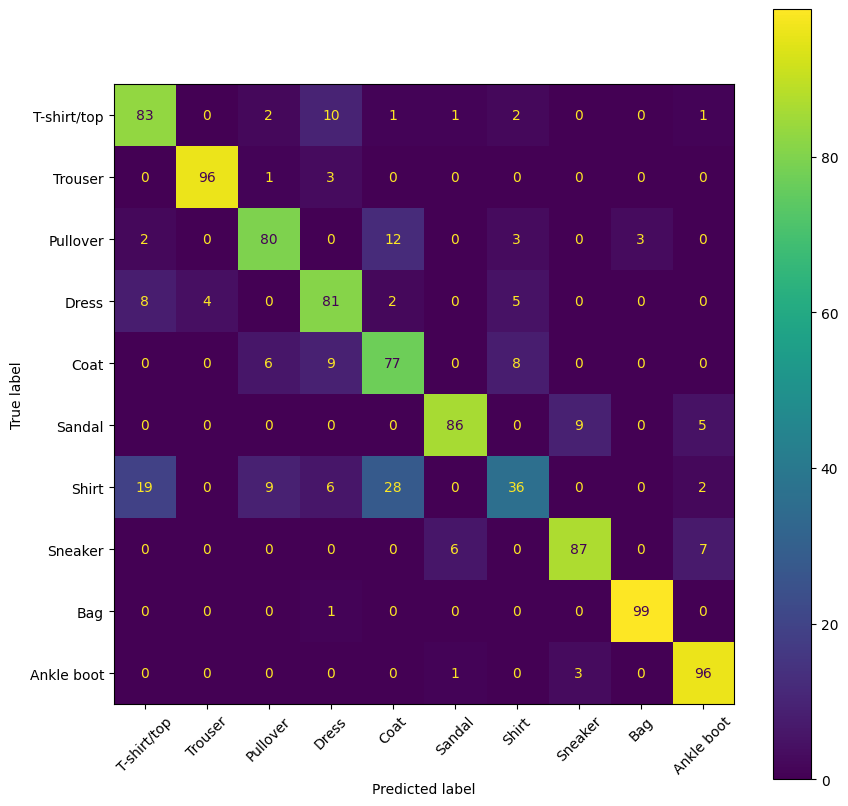

In [71]:
# confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(test_dataset=subset_test_dataset)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
display.plot(xticks_rotation=45, ax=ax)
plt.show()

** CvT **

In [78]:
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="microsoft/cvt-21"
)

transform = transforms.Compose(
    [
    transforms.ToTensor(),
    transforms.Resize(
        size=(
            image_processor.size["shortest_edge"],
            image_processor.size["shortest_edge"]
        )
    ),
    transforms.Lambda(lambda x:torch.cat([x,x,x],0)),
    transforms.Normalize(
        mean=image_processor.image_mean,
        std=image_processor.image_std
    )
   ]
)

In [79]:
# 10.21 사전학습된 CvT 모델

from transformers import CvtForImageClassification

model = CvtForImageClassification.from_pretrained(
    pretrained_model_name_or_path='microsoft/cvt-21',
    num_labels=len(train_dataset.classes),
    id2label={idx:label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("L", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("  L", ssub_name)
      for sssub_name, sssub_module in sssub_module.named_children():
        print("   L", sssub_name)

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


cvt
L encoder
  L stages
   L 0
   L 1
layernorm
classifier


In [80]:
# 10.22 CvT 모델의 스테이지 구조

stages = model.cvt.encoder.stages
print(stages[0])

CvtStage(
  (embedding): CvtEmbeddings(
    (convolution_embeddings): CvtConvEmbeddings(
      (projection): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(2, 2))
      (normalization): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (layers): Sequential(
    (0): CvtLayer(
      (attention): CvtAttention(
        (attention): CvtSelfAttention(
          (convolution_projection_query): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAttentionConvProjection(
              (convolution): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
              (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
            (linear_projection): CvtSelfAttentionLinearProjection()
          )
          (convolution_projection_key): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAtte

In [82]:
# 10.23 셀프 어텐션 적용

batch = next(iter(train_dataloader))
print("이미지 차원:", batch["pixel_values"].shape)

patch_emb_output = stages[0].embedding(batch["pixel_values"])
print("패치 임베딩 차원", patch_emb_output.shape)

batch_size,num_channels, height, width = patch_emb_output.shape
hidden_state = patch_emb_output.view(batch_size, num_channels, height*width).permute(0, 2,1)
print("셀프 어텐션 입력 차원:", hidden_state.shape)

attention_ouput = stages[0].layers[0].attention.attention(hidden_state, height, width)
print("셀프 어텐션 출력 차원 :", attention_ouput.shape)

이미지 차원: torch.Size([32, 3, 224, 224])
패치 임베딩 차원 torch.Size([32, 64, 56, 56])
셀프 어텐션 입력 차원: torch.Size([32, 3136, 64])
셀프 어텐션 출력 차원 : torch.Size([32, 3136, 64])


In [83]:
# 10.24 CvT 모델 학습
args = TrainingArguments(
output_dir="../models/CvT-FashionMNIST",
  save_strategy="epoch",
  eval_strategy="epoch",
  learning_rate=1e-5,
  per_device_train_batch_size=16,
  per_device_eval_batch_size=16,
  num_train_epochs=3,
  weight_decay=0.001,
  load_best_model_at_end=True,
  metric_for_best_model="f1",
  logging_steps=125,
  remove_unused_columns=False,
  seed=7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor
)

trainer.train()

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,F1
1,No log,1.150903,0.699679
2,1.329829,0.700818,0.797062
3,1.329829,0.625792,0.815218


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['swin.encoder.layers.0.blocks.0.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.k_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.k_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.v_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.v_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.o_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.o_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.relative_position_bias.relative_position_bias_table', 'swin.encoder.layers.0.blocks.0.mlp.fc1.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc1.bias', 'swin.encoder.layers.0.blocks.0.mlp.fc2.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc2.bias', 'swin.encoder.layers.0.blocks.1.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.1.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.1.attention.k_proj.weight', 'swin.encode

TrainOutput(global_step=189, training_loss=1.0990584035399098, metrics={'train_runtime': 99.0649, 'train_samples_per_second': 30.283, 'train_steps_per_second': 1.908, 'total_flos': 7.4584635826176e+16, 'train_loss': 1.0990584035399098, 'epoch': 3.0})

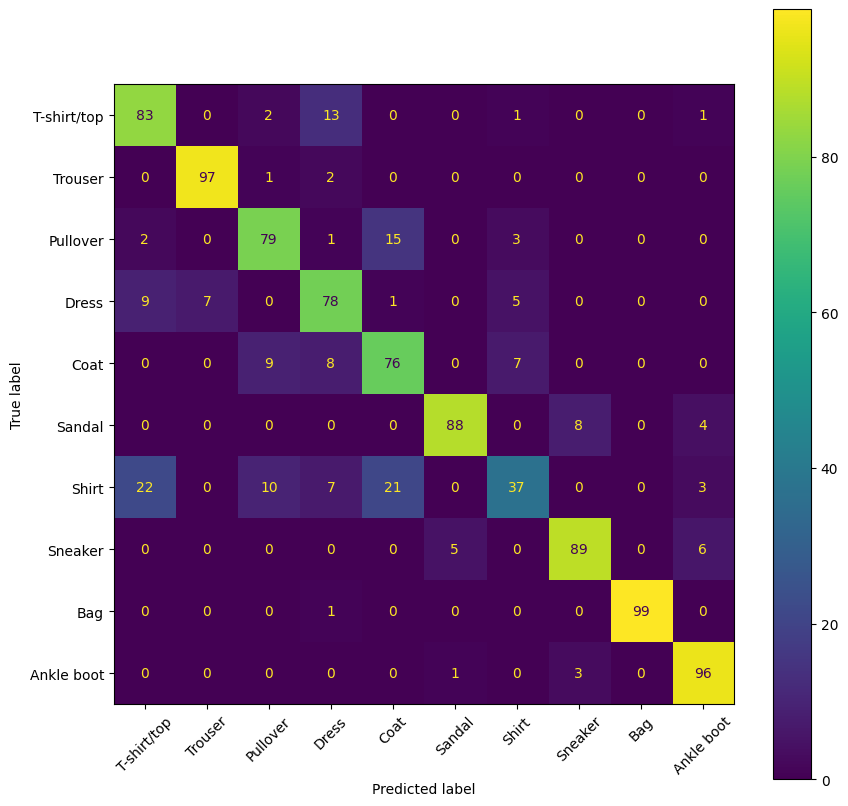

In [84]:
outputs = trainer.predict(test_dataset=subset_test_dataset)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
display.plot(xticks_rotation=45, ax=ax)
plt.show()